In [1]:
import torch
torch.cuda.is_available()

True

In [2]:
import os
from dotenv import load_dotenv
from huggingface_hub import login

load_dotenv()  # 이거 꼭 있어야됨

token = os.getenv("HF_TOKEN")
login(token)


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [3]:
import torch
from src.model import dinosplus_classfier
import torch.nn as nn
from transformers import AutoModel
from src.re_make_Gate import inject_gating, GatedOutputProjection
import mlflow

mlflow.set_tracking_uri("sqlite:///mlruns.db")



# ── run_id로 .pth 다운로드 ──
run_id = "e5065d3b1f3e4fe0908ca275feb5025c"
client = mlflow.tracking.MlflowClient()
local_path = client.download_artifacts(run_id, "best dino v3 splus gate and fc only true.pth", ".")

# ── 구조 만들고 가중치 로드 ──
backbone = AutoModel.from_pretrained("facebook/dinov3-vits16plus-pretrain-lvd1689m")
backbone, hooks = inject_gating(backbone, gate_type="elementwise", keep_cls_ungated=True, target_layers=None)
model = dinosplus_classfier(backbone, num=200)

model.load_state_dict(torch.load(local_path))
model.eval()
print("로드 완료!")

Loading weights:   0%|          | 0/235 [00:00<?, ?it/s]

[inject_gating] 총 12개 중 12개 레이어에 G1 gate 적용
  → 적용 인덱스: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]  (gate_type=elementwise)
로드 완료!


In [4]:
print(model.backbone.layer[0].attention)

DINOv3ViTAttention(
  (k_proj): Linear(in_features=384, out_features=384, bias=False)
  (v_proj): Linear(in_features=384, out_features=384, bias=True)
  (q_proj): Linear(in_features=384, out_features=384, bias=True)
  (o_proj): GatedOutputProjection(
    (original_o_proj): Linear(in_features=384, out_features=384, bias=True)
    (gate_proj): Linear(in_features=384, out_features=384, bias=True)
  )
)


In [11]:
from src.attention_deep import run
import torch
# 허깅페이스 데이터셋
from datasets import load_dataset
ds = load_dataset("zh-plus/tiny-imagenet")
pil_img = ds['valid'][4]['image']

run(model, pil_img=pil_img, save_dir="finetuning_gate_and_fc/attention_maps5")

QK maps  : 12개 레이어
Gate maps: 12개 레이어
저장: finetuning_gate_and_fc/attention_maps5/head_0/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_0/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_1/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_1/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_2/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_2/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_3/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_3/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_4/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_4/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_5/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_5/gate_heatmap.png

완료! Layer 11 | 6개 head → finetuning_gate_and_fc/attention_maps5/head_N/

  통계 분석 결과

① Spearman  (gate평균 vs QK sink score)
   r=-0.3077,  p=0.3306  ❌ 유

({0: tensor([[[[0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00,
             0.0000e+00, 0.0000e+00],
            [0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00,
             0.0000e+00, 0.0000e+00],
            [0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00,
             0.0000e+00, 0.0000e+00],
            ...,
            [0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00,
             0.0000e+00, 0.0000e+00],
            [0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00,
             0.0000e+00, 0.0000e+00],
            [0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00,
             0.0000e+00, 0.0000e+00]],
  
           [[9.9975e-01, 2.8018e-41, 6.9487e-06,  ..., 3.5439e-37,
             4.7630e-37, 5.1329e-38],
            [4.6217e-21, 0.0000e+00, 4.8983e-20,  ..., 2.2972e-15,
             1.5790e-16, 4.5930e-10],
            [9.9987e-01, 1.7699e-39, 4.9195e-06,  ..., 3.5336e-36,
             4.9227e-36, 2.3293e-36],
            ...,
            [1

In [12]:
for i in range(5, 10):
    pil_img = ds['valid'][i]['image']
    run(model, pil_img=pil_img, save_dir=f"finetuning_gate_and_fc/attention_maps{i}")

QK maps  : 12개 레이어
Gate maps: 12개 레이어
저장: finetuning_gate_and_fc/attention_maps5/head_0/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_0/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_1/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_1/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_2/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_2/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_3/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_3/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_4/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_4/gate_heatmap.png
저장: finetuning_gate_and_fc/attention_maps5/head_5/attention_map.png
저장: finetuning_gate_and_fc/attention_maps5/head_5/gate_heatmap.png

완료! Layer 11 | 6개 head → finetuning_gate_and_fc/attention_maps5/head_N/

  통계 분석 결과

① Spearman  (gate평균 vs QK sink score)
   r=0.0769,  p=0.8122  ❌ 유의

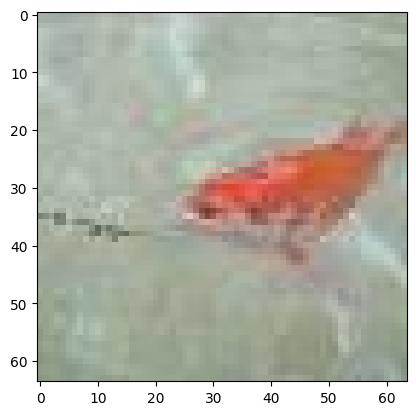

In [6]:
from matplotlib import pyplot as plt
plt.imshow(pil_img)